In [1]:
# Block 1
%load_ext autoreload
%autoreload 1

# Watch the modules these cells call into
%aimport utility
%aimport config
%aimport cnn_detector

import os

# Keras reads the backend before it is imported
os.environ["KERAS_BACKEND"] = "torch"

import numpy as np
import pandas as pd

import keras
import torch

import config
import utility

from cnn_detector import (
    CNN,
    CNN_ANCHOR_COUNT,
    CNN_ANCHOR_CORNERS,
    CNN_GRID_SIZE,
    validate,
)

In [2]:
# Block 2
LESION_TYPE = "mass"
# LESION_TYPE = "calc"

# Seed python, numpy and torch, and pin the cuDNN algorithm
utility.set_deterministic()

config.CNN_WORKSPACE.mkdir(parents=True, exist_ok=True)
config.MODELS_ROOT.mkdir(parents=True, exist_ok=True)

device = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"

print(f"Backend      : {keras.backend.backend()}")
print(f"Device       : {device}")
print(f"Lesion type  : {LESION_TYPE}")
print(f"Canvas       : {config.CNN_IMAGE_SIZE} px, feature stride {config.CNN_FEATURE_STRIDE}")
print(f"Anchor sizes : {config.CNN_ANCHOR_SIZES}")
print(f"Classes      : {config.CLASS_NAMES}")
print(f"Folds        : {config.OOF_FOLDS}")
print(f"Norm         : {config.CNN_NORM}, groups {config.CNN_GROUP_NORM_GROUPS}")
print(f"Kernel L2    : {config.CNN_KERNEL_L2}, label smoothing {config.CNN_LABEL_SMOOTHING}")
print(f"Class fork   : {config.CNN_CLASS_FORK_FILTERS} filters, 1 conv")
print(f"Augment      : scale {config.CNN_AUGMENT_SCALE_RANGE}, translate {config.CNN_AUGMENT_TRANSLATE_FRACTION}")
print(f"Gamma range  : {config.CNN_AUGMENT_GAMMA_RANGE}")
print(f"Workspace    : {config.CNN_WORKSPACE}")
print(f"Models       : {config.MODELS_ROOT}")

Backend      : torch
Device       : NVIDIA GeForce RTX 3060 Laptop GPU
Lesion type  : mass
Canvas       : 768 px, feature stride 8
Anchor sizes : (24, 32, 48, 80)
Classes      : ('benign', 'malignant')
Folds        : (0, 1, 2, 3, 4)
Norm         : group, groups 16
Kernel L2    : 0.0001, label smoothing 0.0
Class fork   : 64 filters, 1 conv
Augment      : scale (0.8, 1.25), translate 0.1
Gamma range  : (0.75, 1.25)
Workspace    : C:\Users\User\Desktop\sch work\fyp\01_cnn_workspace
Models       : C:\Users\User\Desktop\sch work\fyp\models


In [3]:
# Block 3
# Load metadata
metadata = pd.read_csv(config.PROJECT_ROOT / f"{LESION_TYPE}_metadata.csv")

display(metadata.head())

print(f"Rows: {len(metadata):,}")
print(f"Unique mammograms: {metadata['full_image'].nunique():,}")
print(f"Unique lesions: {metadata['mask_image'].nunique():,}")

,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,...,split,fold,full_image,crop_image,mask_image,breast_mask,breast_xmin,breast_ymin,breast_xmax,breast_ymax
0,P_00016,4,LEFT,CC,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,...,test,-1,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,198,0,471,1023
1,P_00016,4,LEFT,MLO,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,...,test,-1,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,0,0,374,1023
2,P_00017,2,LEFT,CC,1,mass,ROUND,CIRCUMSCRIBED,4,MALIGNANT,...,trainval,0,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,0,0,554,1023
3,P_00017,2,LEFT,MLO,1,mass,ROUND,ILL_DEFINED,4,MALIGNANT,...,trainval,0,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,0,0,576,1023
4,P_00032,3,RIGHT,CC,1,mass,ROUND,OBSCURED,0,BENIGN,...,trainval,2,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,153,0,528,1023


Rows: 1,696
Unique mammograms: 1,592
Unique lesions: 1,696


In [4]:
# Block 4
# Per-mammogram split, then the fold 0 validation set
groups = utility.group_mammograms(metadata)

# Out-of-fold predictions cover the trainval split only; test stays held out
trainval_df = groups[groups["split"] == "trainval"].reset_index(drop=True)
test_df = groups[groups["split"] == "test"].reset_index(drop=True)

train_df, val_df = utility.oof_split(trainval_df, config.VAL_FOLD)

print(f"Trainval: {len(trainval_df):,} mammograms, folds {trainval_df['fold'].value_counts().sort_index().to_dict()}")
print(f"Test    : {len(test_df):,} mammograms, held out")
print(f"Fold {config.VAL_FOLD}: train {len(train_df):,}, val {len(val_df):,}")

Trainval: 1,272 mammograms, folds {0: 264, 1: 248, 2: 248, 3: 253, 4: 259}
Test    : 320 mammograms, held out
Fold 0: train 1,008, val 264


In [5]:
# Block 5
# Prepare one sample through the CNN pipeline
cnn = CNN()

image, mask, boxes, class_labels = cnn.prepare(trainval_df.iloc[0])
labels, deltas, class_targets = cnn.dense_targets(boxes, class_labels, cnn.breast_grid(mask))

print(f"Canvas    : {image.shape}")
print(
    f"Grid      : {CNN_GRID_SIZE} x {CNN_GRID_SIZE}, {CNN_ANCHOR_COUNT} anchors per cell = {len(CNN_ANCHOR_CORNERS):,}"
)
print(f"GT boxes  : {len(boxes)} with classes {class_labels.tolist()}")
print(f"Positives : {int((labels == 1).sum())}")
print(f"Ignored   : {int((labels == -1).sum())}")

# Each positive anchor's class target must trace back to the GT box it matched
anchors = np.nonzero(labels.reshape(-1) == 1)[0]
matched = utility.iou_many_vs_many(CNN_ANCHOR_CORNERS, boxes).argmax(axis=1)
mismatches = int((class_targets.reshape(-1)[anchors] != class_labels[matched][anchors]).sum())

print(f"Class mismatches between positive anchors and their matched GT: {mismatches}")

Canvas    : (768, 768)
Grid      : 96 x 96, 4 anchors per cell = 36,864
GT boxes  : 1 with classes [1]
Positives : 1
Ignored   : 27407
Class mismatches between positive anchors and their matched GT: 0


In [6]:
# Block 6
# Inspect one training batch of targets
train_loader = cnn.dataset(train_df)

images, targets = train_loader[0]

print(f"Batch shape      : {images.shape}")
print(f"Objectness shape : {targets['objectness'].shape}")
print(f"Box shape        : {targets['box'].shape}")
print(f"Class shape      : {targets['classes'].shape}")
print(f"Positives        : {int((targets['objectness'] == 1).sum()):,}")
print(f"Negatives        : {int((targets['objectness'] == 0).sum()):,}")
print(f"Ignored          : {int((targets['objectness'] == -1).sum()):,}")
print(f"Class targets    : {int((targets['classes'][..., 0] >= 0).sum()):,}")
print(f"Train batches    : {len(train_loader):,}")

Batch shape      : (4, 768, 768, 1)
Objectness shape : (4, 96, 96, 4)
Box shape        : (4, 96, 96, 4, 5)
Class shape      : (4, 96, 96, 4, 2)
Positives        : 73
Negatives        : 1,460
Ignored          : 145,923
Class targets    : 73
Train batches    : 252


In [7]:
# Block 7
# Build the dense model and print its summary
cnn.build()
cnn.model.summary()

Model: "dense_objectness"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 768, 768,  │          0 │ -                 │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 768, 768,  │        288 │ image[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalization │ (None, 768, 768,  │         64 │ conv2d[0][0]      │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 768, 768,  │          0 │ group_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 768, 768,  │      9,216 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 768, 768,  │         64 │ conv2d_1[0][0]    │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 768, 768,  │          0 │ group_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 384, 384,  │      9,216 │ re_lu_1[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 384, 384,  │         64 │ conv2d_2[0][0]    │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 384, 384,  │          0 │ group_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 384, 384,  │      9,216 │ re_lu_2[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 384, 384,  │         64 │ conv2d_3[0][0]    │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 384, 384,  │          0 │ group_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 192, 192,  │     18,432 │ re_lu_3[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 192, 192,  │        128 │ conv2d_4[0][0]    │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_4 (ReLU)      │ (None, 192, 192,  │          0 │ group_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 192, 192,  │     36,864 │ re_lu_4[0][0]   

 Total params: 789,692 (3.01 MB)

 Trainable params: 789,692 (3.01 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Block 8
# One model per fold; a completed fold is skipped, so re-running resumes the rest
print(
    f"Loss     : objectness BCE, box weight {config.CNN_BOX_LOSS_WEIGHT}, "
    f"class weight {config.CNN_CLASS_LOSS_WEIGHT}"
)
print(
    f"Class    : weight {config.CNN_CLASS_LOSS_WEIGHT_START} -> {config.CNN_CLASS_LOSS_WEIGHT} "
    f"over {config.CNN_CLASS_LOSS_RAMP_EPOCHS} epochs, gated off the trunk"
)
print(f"Schedule : warmup {config.CNN_WARMUP_EPOCHS} epoch, cosine over {config.CNN_NUM_EPOCHS} epochs")
print(f"Export   : stacker floor {config.CNN_STACKER_SCORE_THRESHOLD}, " f"top {config.CNN_STACKER_TOP_K} per image")


oof_summary = {}

for fold in config.OOF_FOLDS:
    oof_summary[fold] = cnn.oof_fold(trainval_df, fold, LESION_TYPE, export=False)

# Export each fold's records and its ranked candidate feed for the stacker
exported = cnn.export_folds(trainval_df, LESION_TYPE)

pd.DataFrame.from_dict(exported, orient="index")

Loss     : objectness BCE, box weight 1.0, class weight 21.0
Class    : weight 1.0 -> 21.0 over 5 epochs, gated off the trunk
Schedule : warmup 1 epoch, cosine over 50 epochs
Export   : stacker floor 0.05, top 100 per image
Fold 0: complete (val AP50 0.5652, 3524 records), skipping
Epoch | Loss   | obj    | box    | cls    | AP50   | mAP50  | P      | R      | F1     | Det
1     | 0.4001 | 0.2085 | 0.0656 | 0.0420 | 0.0271 | 0.0066 | 0.0000 | 0.0000 | 0.0000 | 0.0
2     | 0.3774 | 0.1141 | 0.0197 | 0.0328 | 0.0847 | 0.0302 | 0.0536 | 0.4199 | 0.0951 | 8.3
3     | 0.4806 | 0.0963 | 0.0165 | 0.0324 | 0.2007 | 0.0954 | 0.0829 | 0.5125 | 0.1428 | 6.6
4     | 0.5911 | 0.0897 | 0.0147 | 0.0317 | 0.1686 | 0.0861 | 0.0867 | 0.4448 | 0.1451 | 5.5
5     | 0.6928 | 0.0821 | 0.0140 | 0.0308 | 0.1805 | 0.1076 | 0.0710 | 0.5018 | 0.1243 | 7.5
6     | 0.7935 | 0.0752 | 0.0124 | 0.0308 | 0.2636 | 0.1225 | 0.0777 | 0.5979 | 0.1375 | 8.2
7     | 0.7885 | 0.0744 | 0.0131 | 0.0308 | 0.3011 | 0.1402 | 0.08

,fold,seed,epochs,best_epoch,best_val_ap50,record_count,image_count,fingerprint,candidate_count,exported
0,0,42,50,44,0.565217,3524,264,090b6beb81b9,12754,True
1,1,42,50,41,0.523099,3049,248,090b6beb81b9,12275,True
2,2,42,50,50,0.524296,3528,248,090b6beb81b9,12202,True
3,3,42,50,49,0.551045,3233,253,090b6beb81b9,12330,True
4,4,42,50,46,0.521873,4092,259,090b6beb81b9,12788,True


In [9]:
# Block 9
# Coverage check: each fold's records stay inside their own fold and no test mammogram appears
fold_records_paths = {fold: config.fold_paths("cnn", LESION_TYPE, fold)["records"] for fold in config.OOF_FOLDS}

records_by_fold = utility.oof_records(fold_records_paths)
manifest = utility.read_oof_manifest(config.oof_manifest_path("cnn", LESION_TYPE))

print(f"Folds complete: {sorted(manifest['folds'])}")

trainval_ids = pd.Series([utility.mammogram_id(path) for path in trainval_df["full_image"]], index=trainval_df.index)
test_ids = {utility.mammogram_id(path) for path in test_df["full_image"]}

covered = []

for fold, frame in records_by_fold.items():
    fold_ids = set(frame["image_id"])
    expected_ids = set(trainval_ids[trainval_df["fold"] == fold])

    covered.extend(sorted(fold_ids))

    print(
        f"Fold {fold}: {frame['image_id'].nunique():,} mammograms, {len(frame):,} records, "
        f"outside its own fold: {len(fold_ids - expected_ids)}, "
        f"images with detections: {len(fold_ids)}/{len(expected_ids)}"
    )

print(f"OOF mammograms: {len(covered):,} rows, {len(set(covered)):,} unique of {len(trainval_df):,} trainval")
print(f"Test mammograms inside the OOF records: {len(set(covered) & test_ids)}")

Folds complete: ['0', '1', '2', '3', '4']
Fold 0: 264 mammograms, 3,524 records, outside its own fold: 0, images with detections: 264/264
Fold 1: 248 mammograms, 3,049 records, outside its own fold: 0, images with detections: 248/248
Fold 2: 248 mammograms, 3,528 records, outside its own fold: 0, images with detections: 248/248
Fold 3: 253 mammograms, 3,233 records, outside its own fold: 0, images with detections: 253/253
Fold 4: 259 mammograms, 4,092 records, outside its own fold: 0, images with detections: 259/259
OOF mammograms: 1,272 rows, 1,272 unique of 1,272 trainval
Test mammograms inside the OOF records: 0


In [10]:
# Block 10
# Fold manifest table
manifest_df = pd.DataFrame.from_dict(manifest["folds"], orient="index").sort_index()
manifest_df.index.name = "fold"

display(manifest_df)

,fold,seed,epochs,best_epoch,best_val_ap50,record_count,image_count,fingerprint,candidate_count,exported
fold,,,,,,,,,,
0,0,42,50,44,0.565217,3524,264,090b6beb81b9,12754,True
1,1,42,50,41,0.523099,3049,248,090b6beb81b9,12275,True
2,2,42,50,50,0.524296,3528,248,090b6beb81b9,12202,True
3,3,42,50,49,0.551045,3233,253,090b6beb81b9,12330,True
4,4,42,50,46,0.521873,4092,259,090b6beb81b9,12788,True


infer:   0%|          | 0/66 [00:00<?, ?it/s]

Fold 0: 264 mammograms


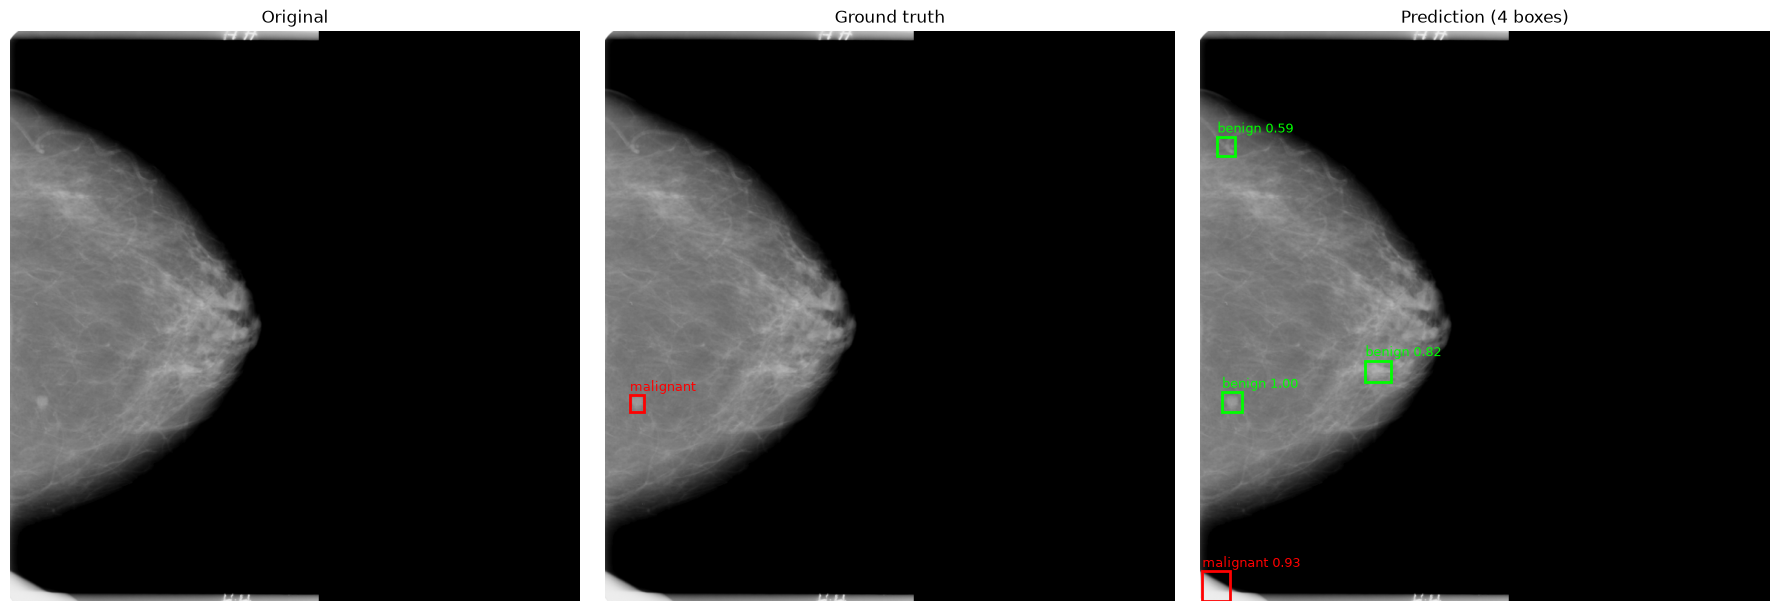

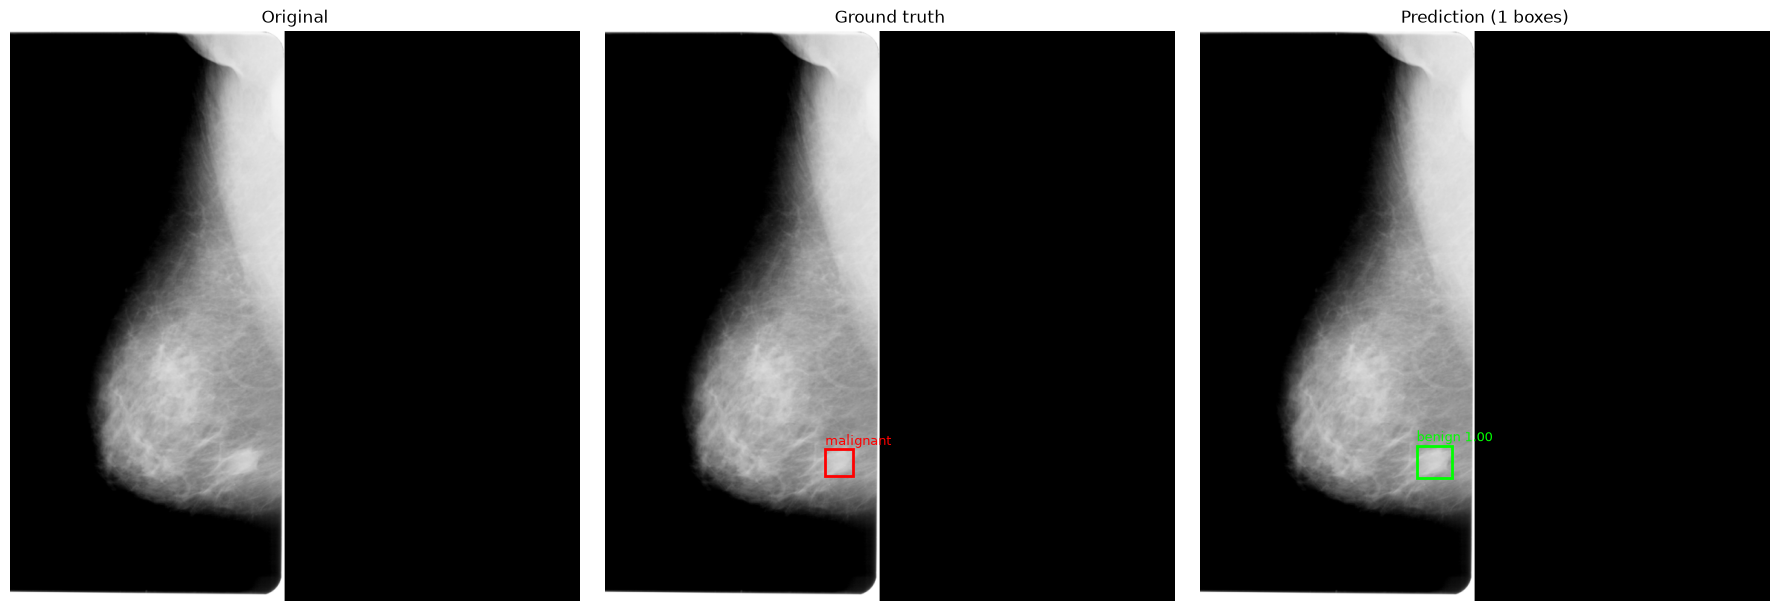

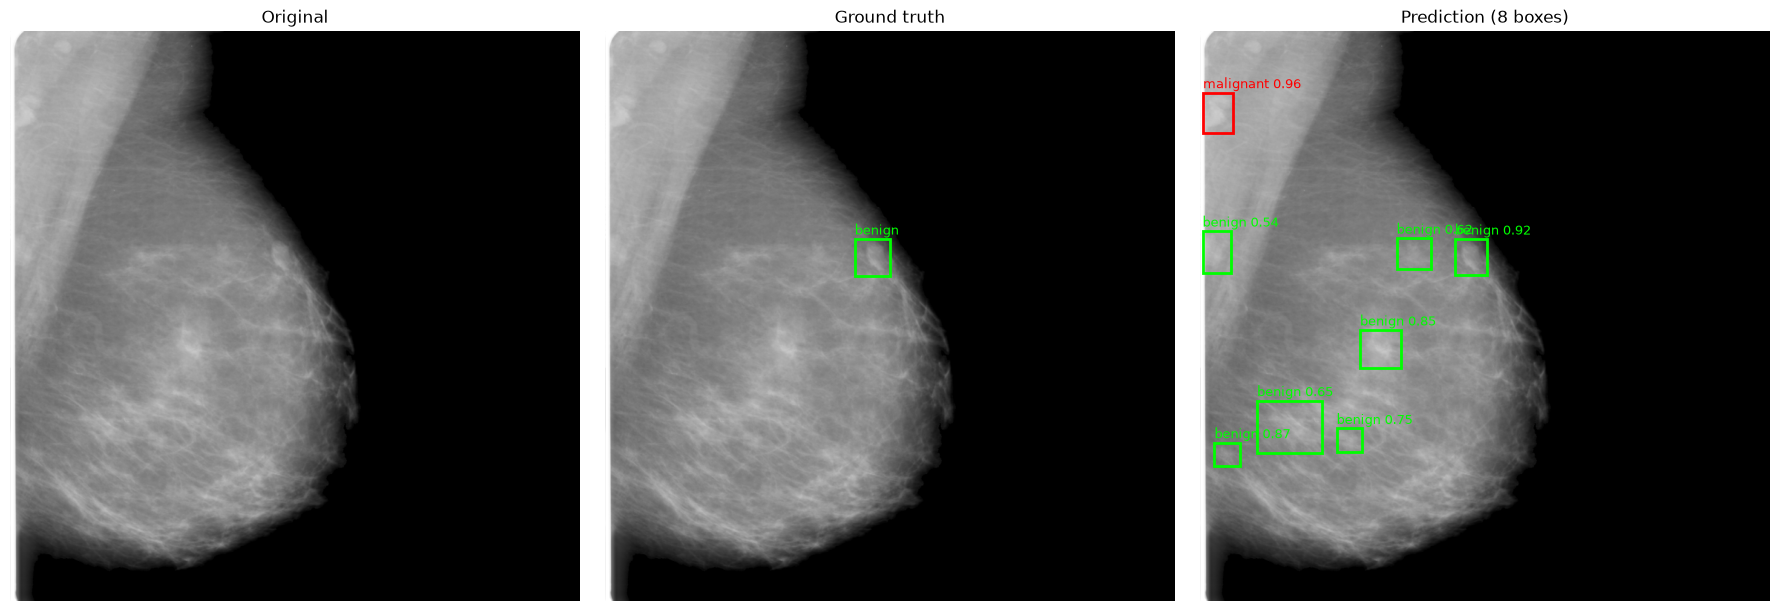

infer:   0%|          | 0/62 [00:00<?, ?it/s]

Fold 1: 248 mammograms


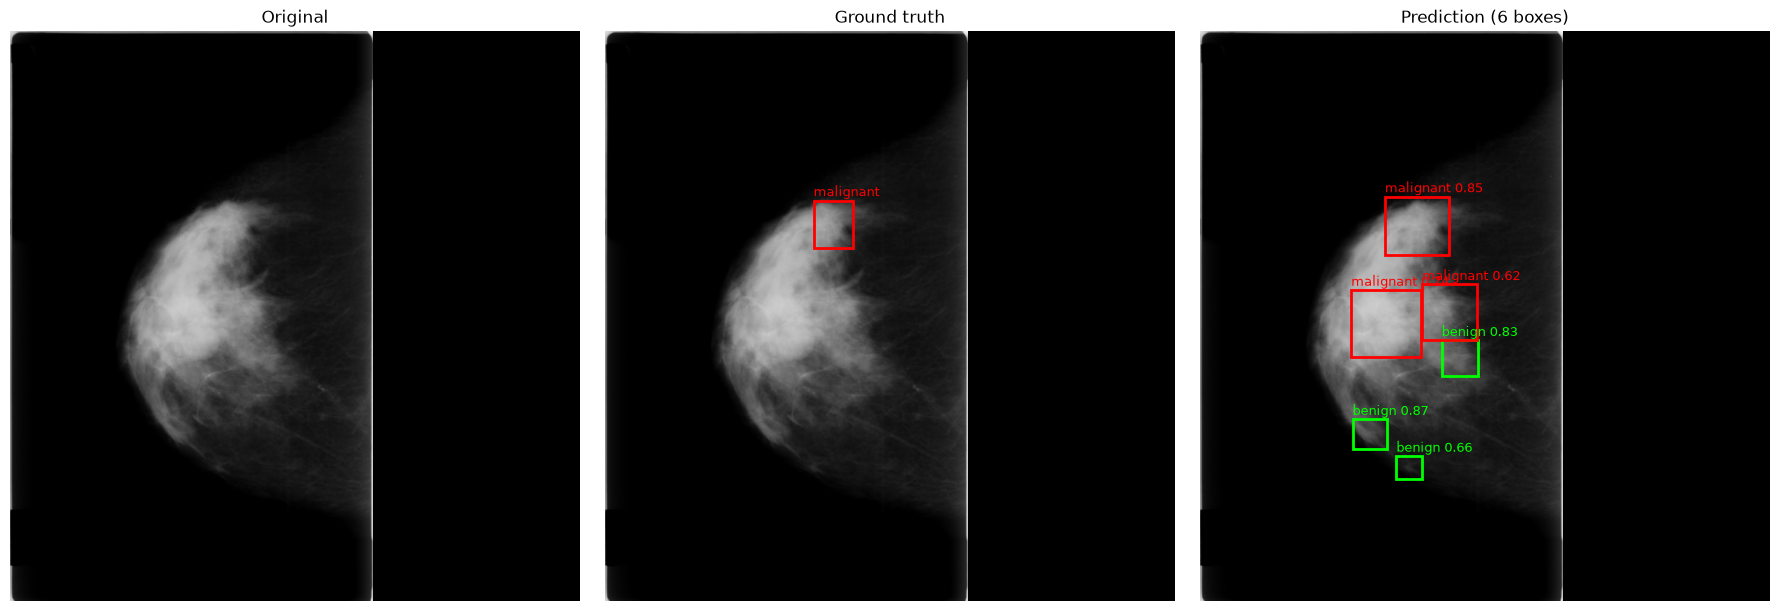

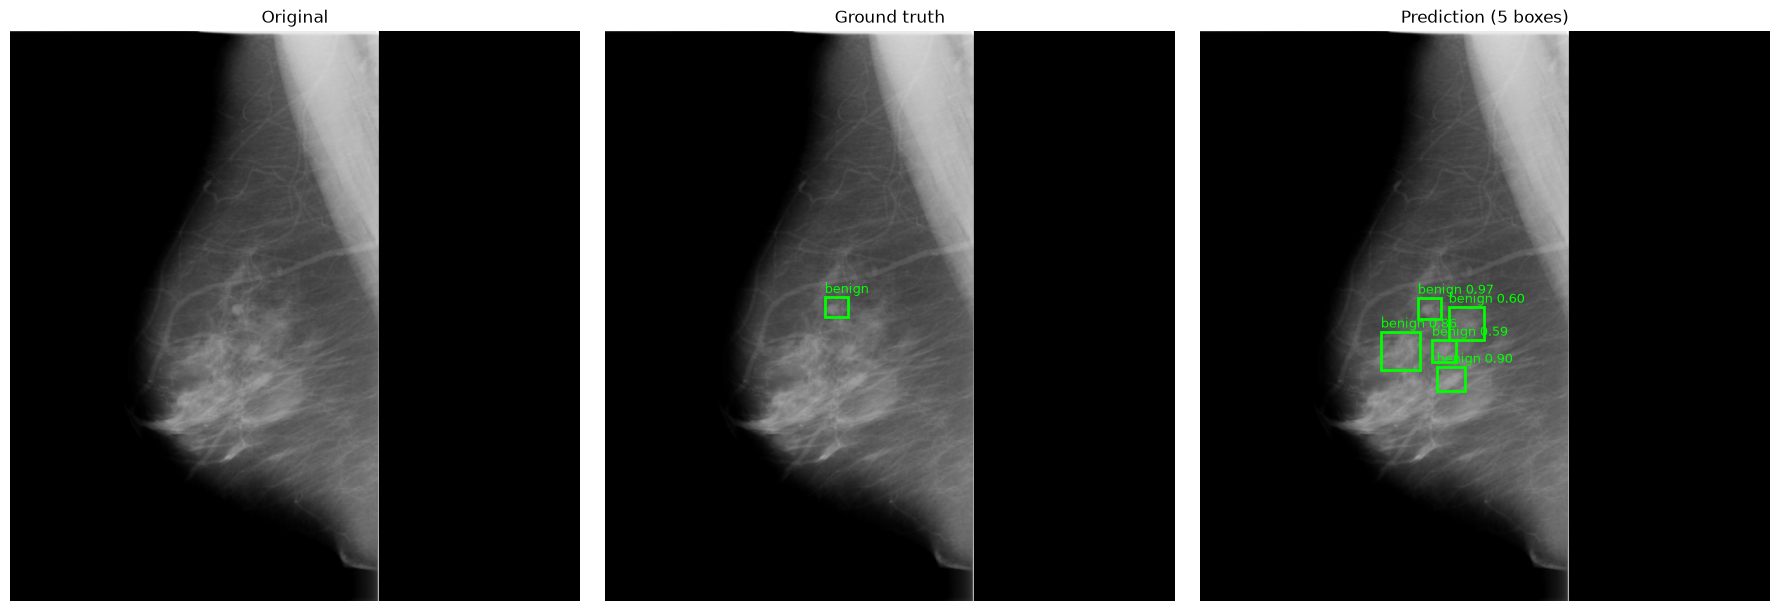

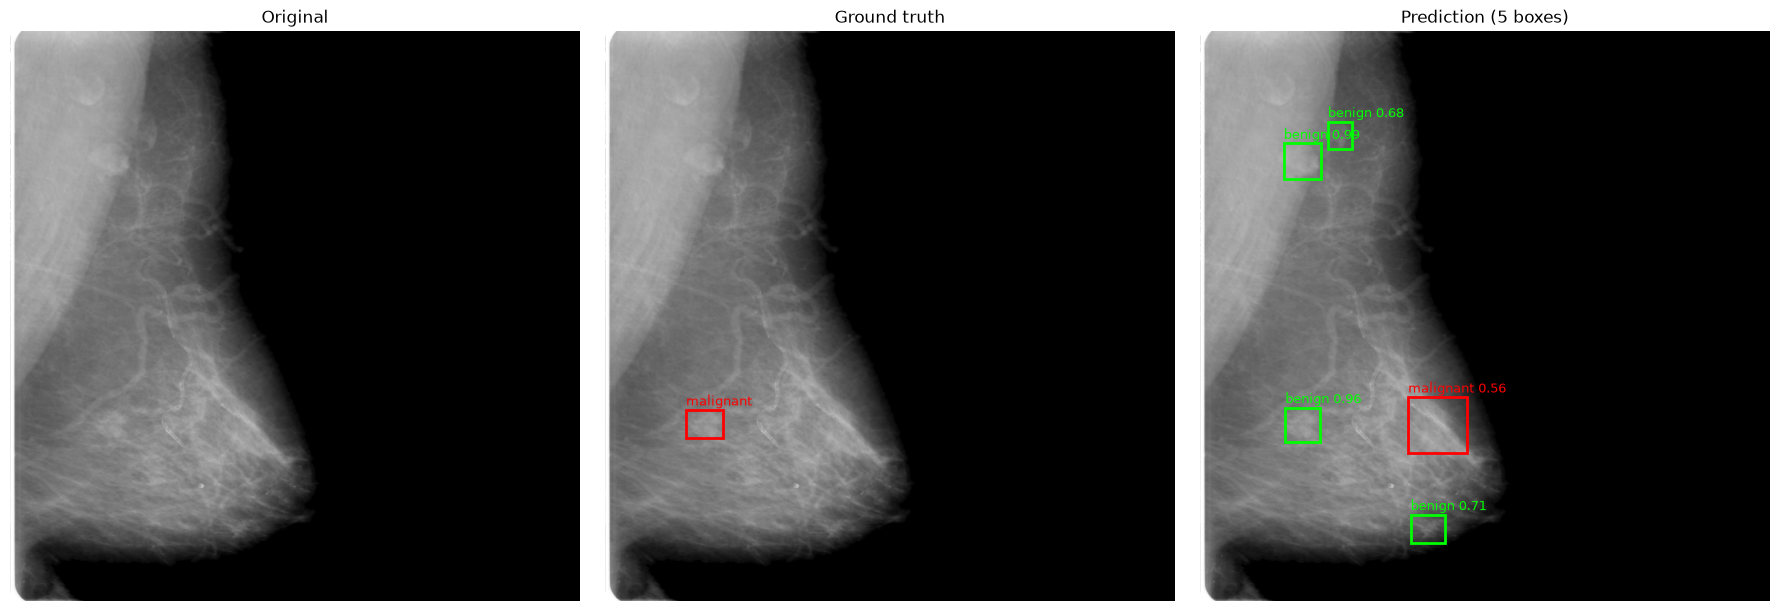

infer:   0%|          | 0/62 [00:00<?, ?it/s]

Fold 2: 248 mammograms


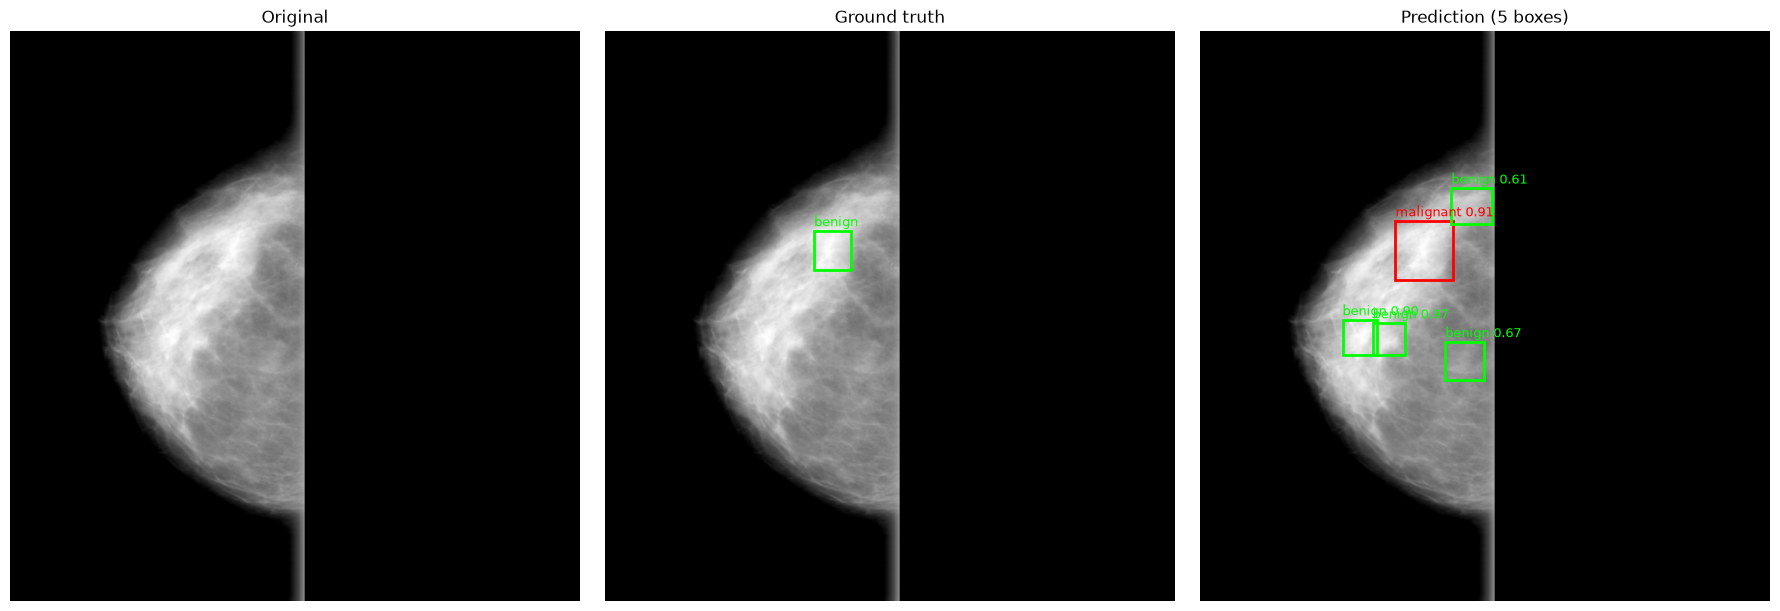

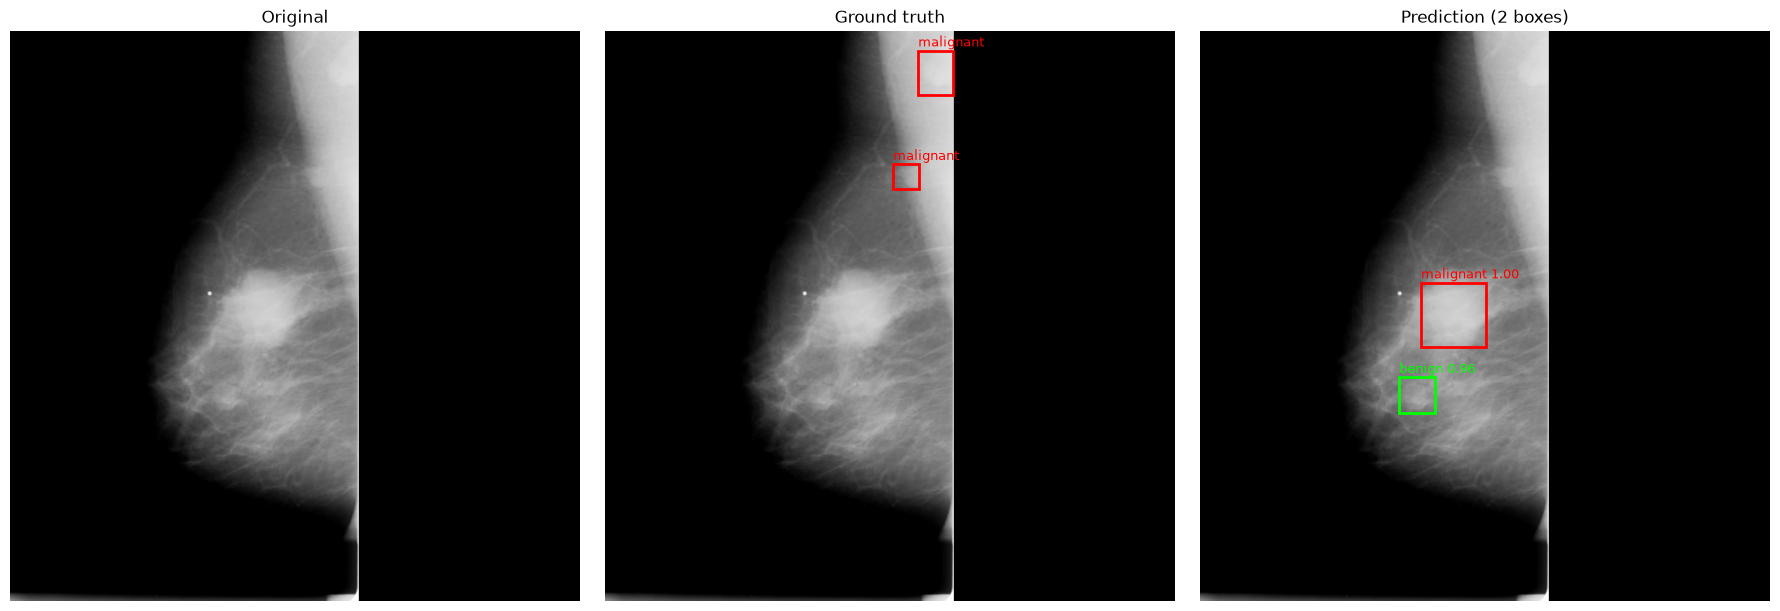

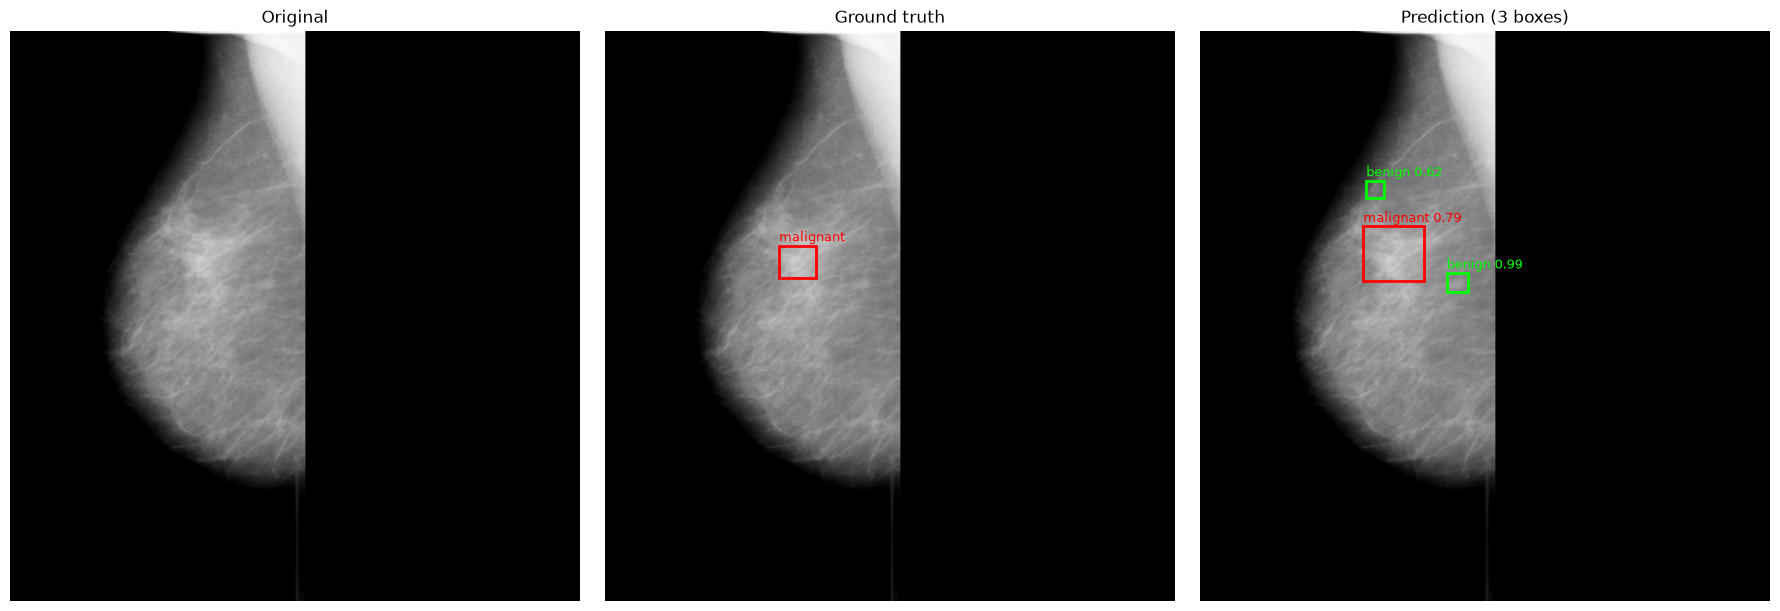

infer:   0%|          | 0/64 [00:00<?, ?it/s]

Fold 3: 253 mammograms


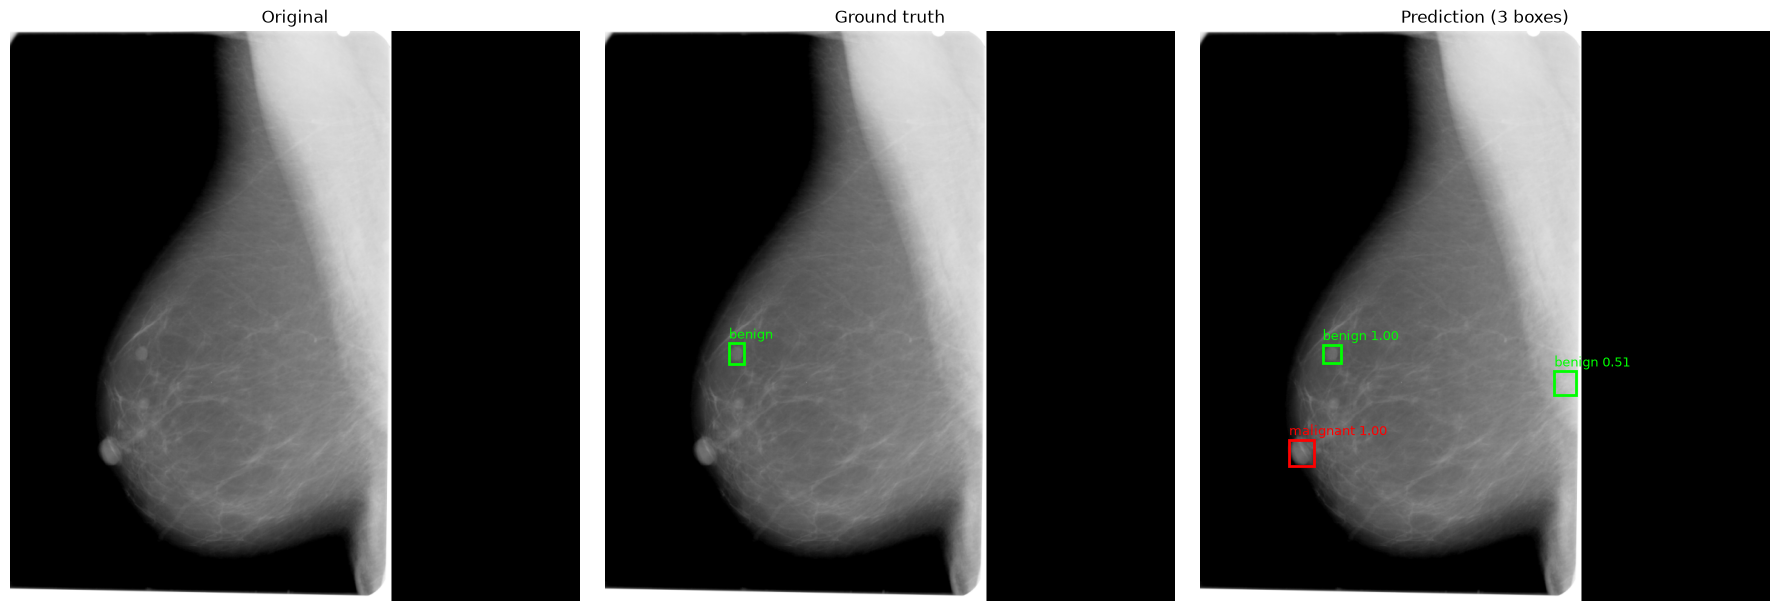

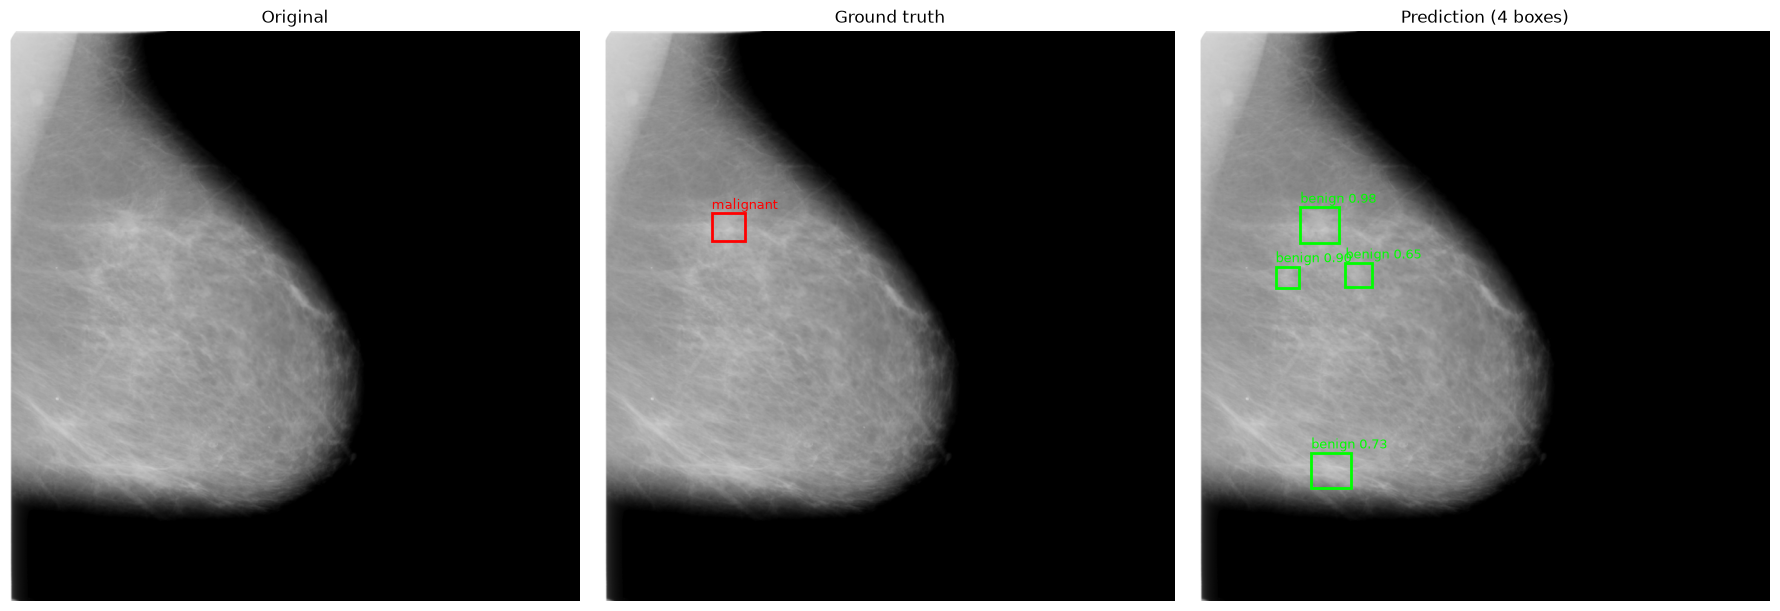

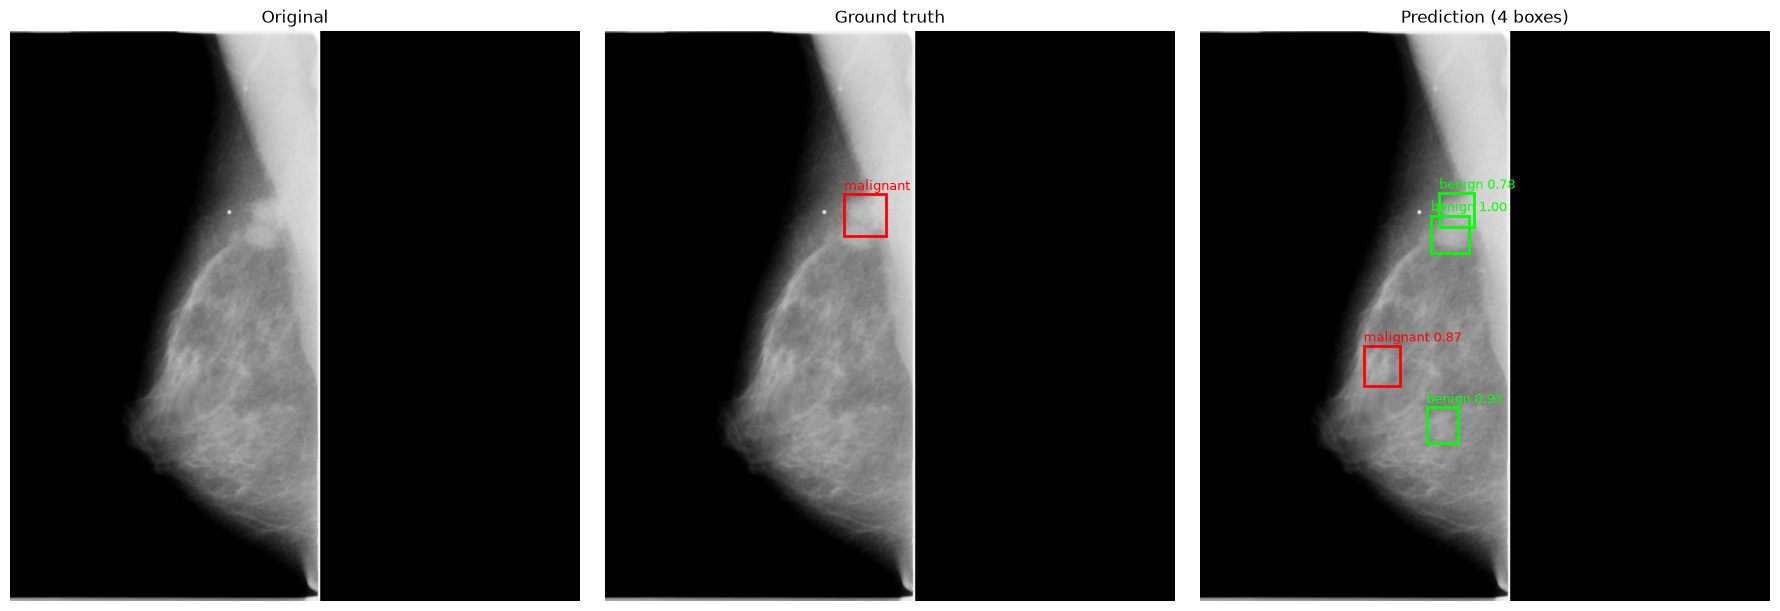

infer:   0%|          | 0/65 [00:00<?, ?it/s]

Fold 4: 259 mammograms


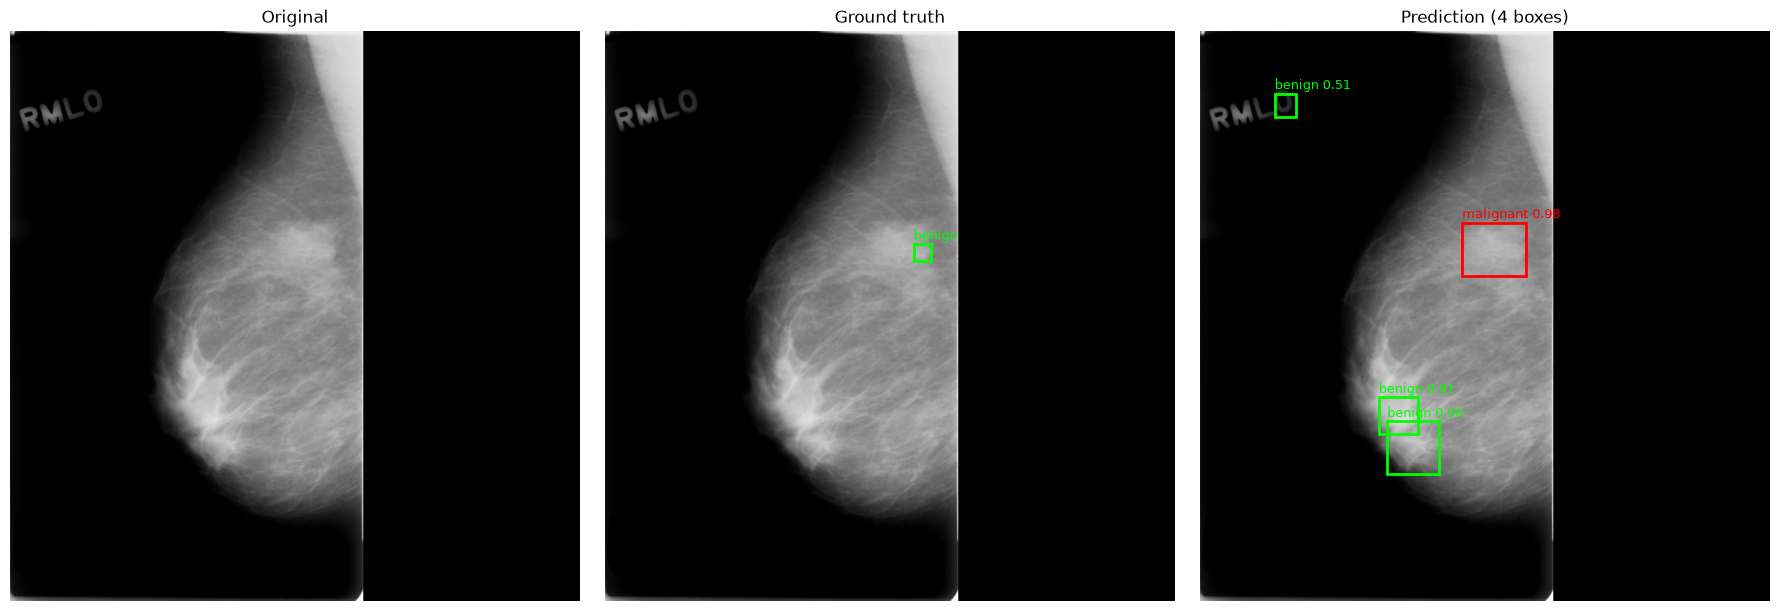

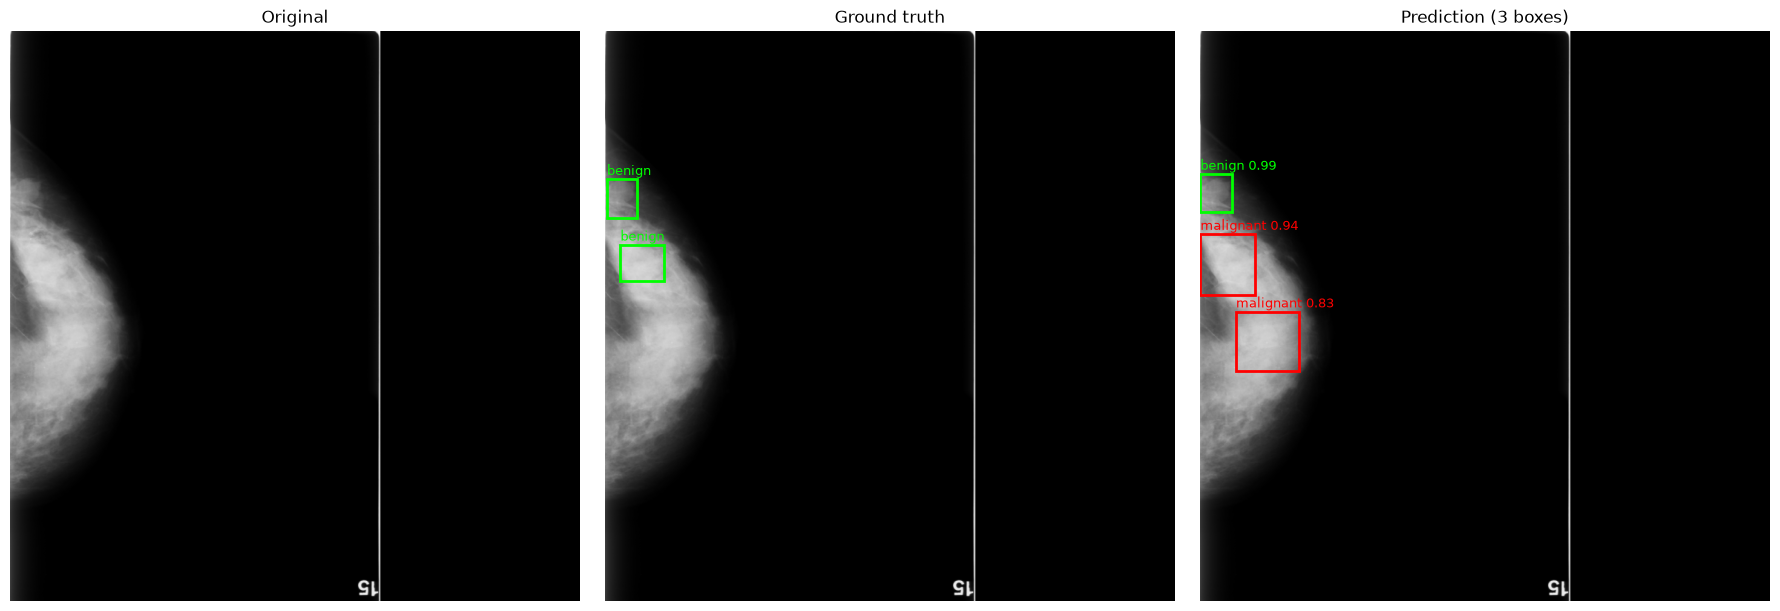

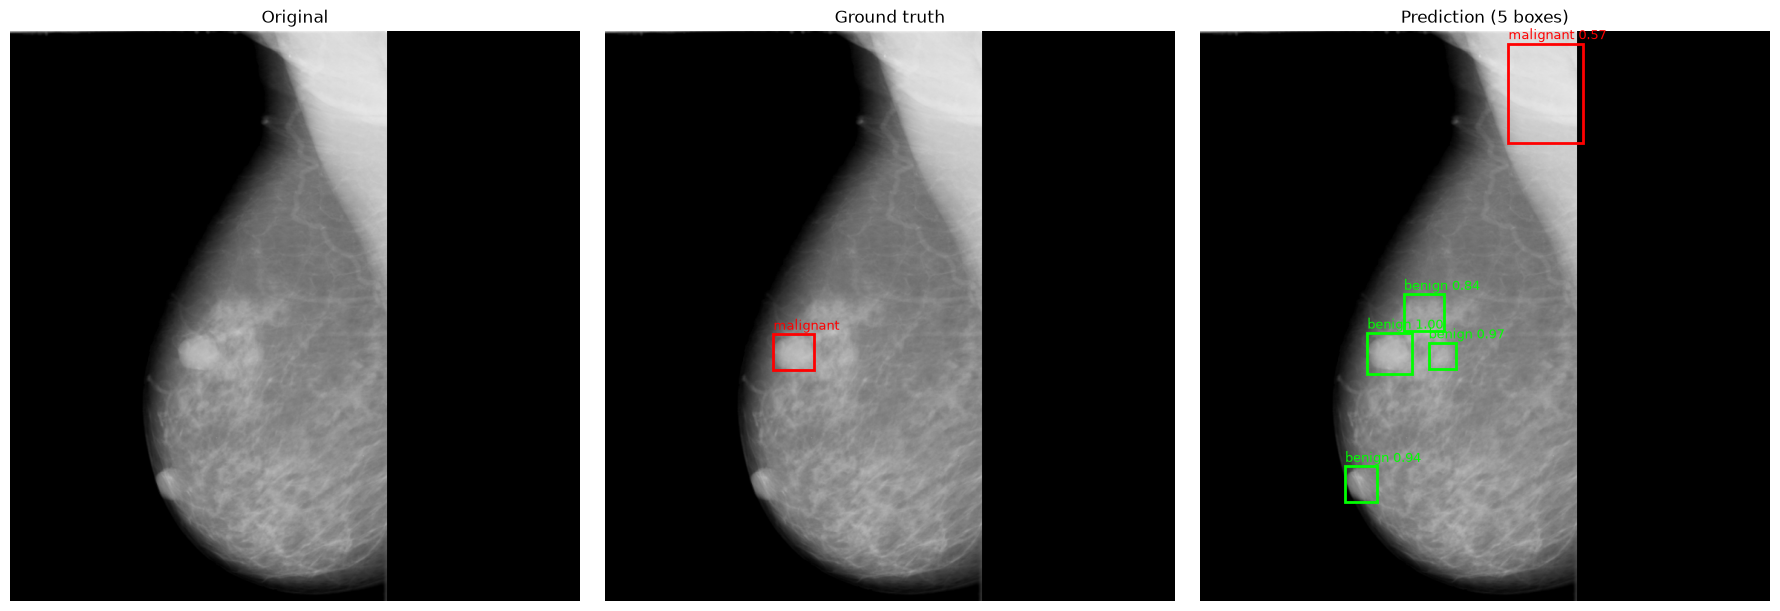

In [11]:
# Block 11
# Qualitative check: three held-out mammograms per fold at the operating threshold
fold_predictions = {}

for fold in config.OOF_FOLDS:
    scorer = CNN(config.fold_model_path("cnn", LESION_TYPE, fold))
    scorer.load()

    val_fold_df = trainval_df[trainval_df["fold"] == fold].reset_index(drop=True)
    fold_predictions[fold] = scorer.infer(val_fold_df)

    print(f"Fold {fold}: {len(val_fold_df):,} mammograms")

    for index in np.linspace(0, len(val_fold_df) - 1, 3, dtype=int):
        image, gt_boxes, gt_labels, boxes, scores, labels = scorer.predict_image(val_fold_df.iloc[index])

        utility.visualize_detections(image, gt_boxes, gt_labels, boxes, scores, labels, config.CLASS_NAMES)

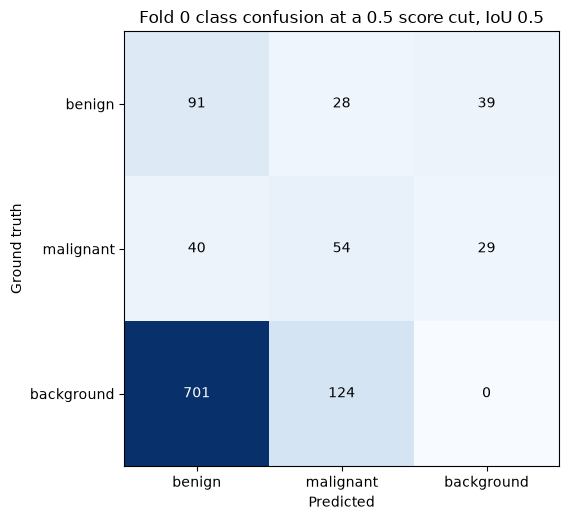

Fold 0
True positives  : 145
False negatives : 68
False positives : 825
Misclassified   : 68


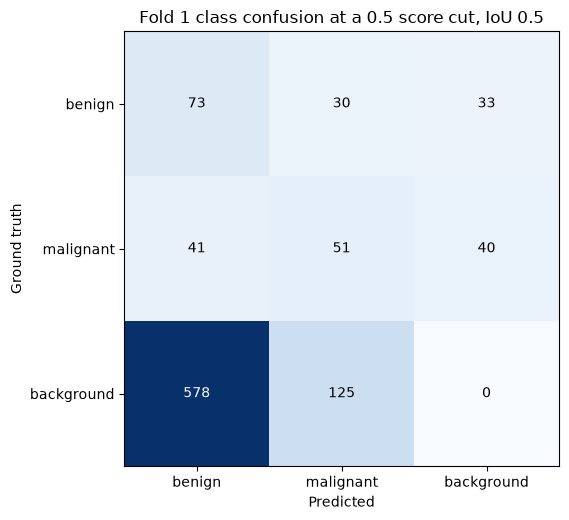

Fold 1
True positives  : 124
False negatives : 73
False positives : 703
Misclassified   : 71


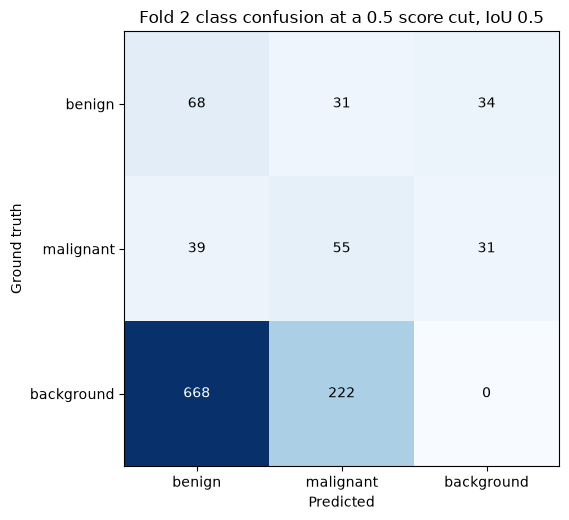

Fold 2
True positives  : 123
False negatives : 65
False positives : 890
Misclassified   : 70


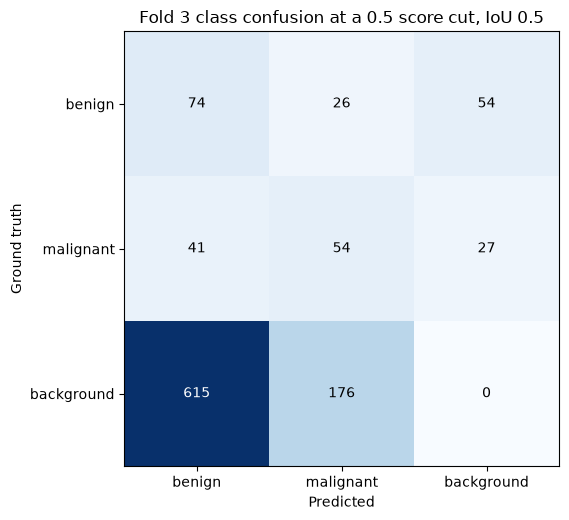

Fold 3
True positives  : 128
False negatives : 81
False positives : 791
Misclassified   : 67


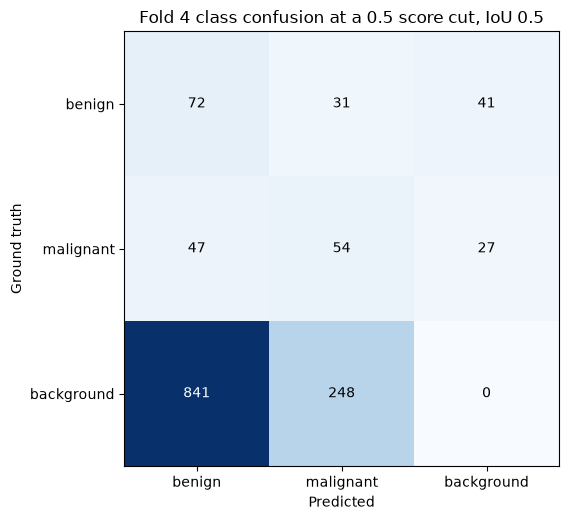

Fold 4
True positives  : 126
False negatives : 68
False positives : 1,089
Misclassified   : 78


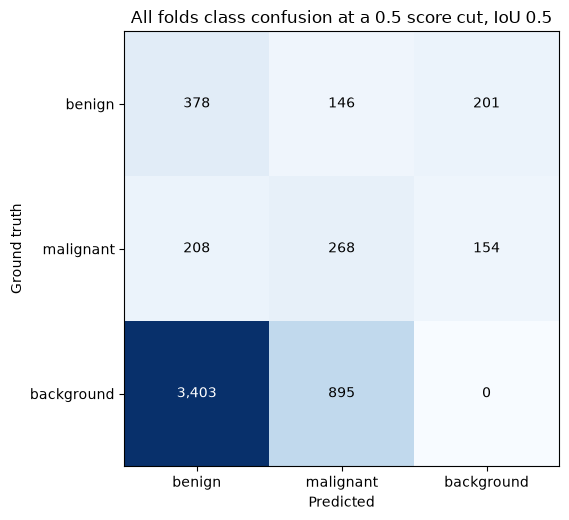

All folds
True positives  : 646
False negatives : 355
False positives : 4,298
Misclassified   : 354


In [12]:
# Block 12
# Class confusion per fold, plus the pooled matrix
classes = list(config.CLASS_NAMES)

fold_confusions = {
    fold: utility.detection_confusion(records, iou_threshold=config.CNN_IOU_THRESHOLD, class_names=config.CLASS_NAMES)
    for fold, records in fold_predictions.items()
}

confusions = {f"fold {fold}": frame for fold, frame in fold_confusions.items()}

# Pooling the per-fold matrices is the same as one confusion over every fold's records
confusions["all folds"] = sum(fold_confusions.values())

for name, confusion in confusions.items():
    utility.plot_confusion(
        confusion,
        title=(
            f"{name.capitalize()} class confusion at a {config.CNN_INFERENCE_SCORE_THRESHOLD} score cut, "
            f"IoU {config.CNN_IOU_THRESHOLD}"
        ),
    )

    true_positive = int(np.trace(confusion.loc[classes, classes].to_numpy()))
    false_negative = int(confusion.loc[classes, "background"].sum())
    false_positive = int(confusion.loc["background", classes].sum())
    misclassified = int(confusion.loc[classes, classes].to_numpy().sum() - true_positive)

    print(f"{name.capitalize()}")
    print(f"True positives  : {true_positive:,}")
    print(f"False negatives : {false_negative:,}")
    print(f"False positives : {false_positive:,}")
    print(f"Misclassified   : {misclassified:,}")

In [13]:
# Block 13
# The five held-out fold checkpoints above, against the single model retrained on all trainval
import final_retrain

fold_checkpoints = sorted(config.MODELS_ROOT.glob(f"{LESION_TYPE}_cnn_fold*.keras"))
full_model = final_retrain.load_or_train("cnn")

print(f"Fold ensemble: {len(fold_checkpoints)} checkpoints, {config.MODELS_ROOT}")
print(f"Full retrain : {full_model.name}, {full_model.stat().st_size / 1e6:.1f} MB")

cnn: mass_cnn_full.keras is already on disk, not retraining
Fold ensemble: 5 checkpoints, C:\Users\User\Desktop\sch work\fyp\models
Full retrain : mass_cnn_full.keras, 9.7 MB


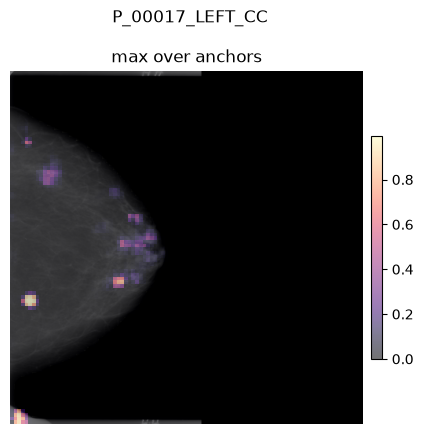

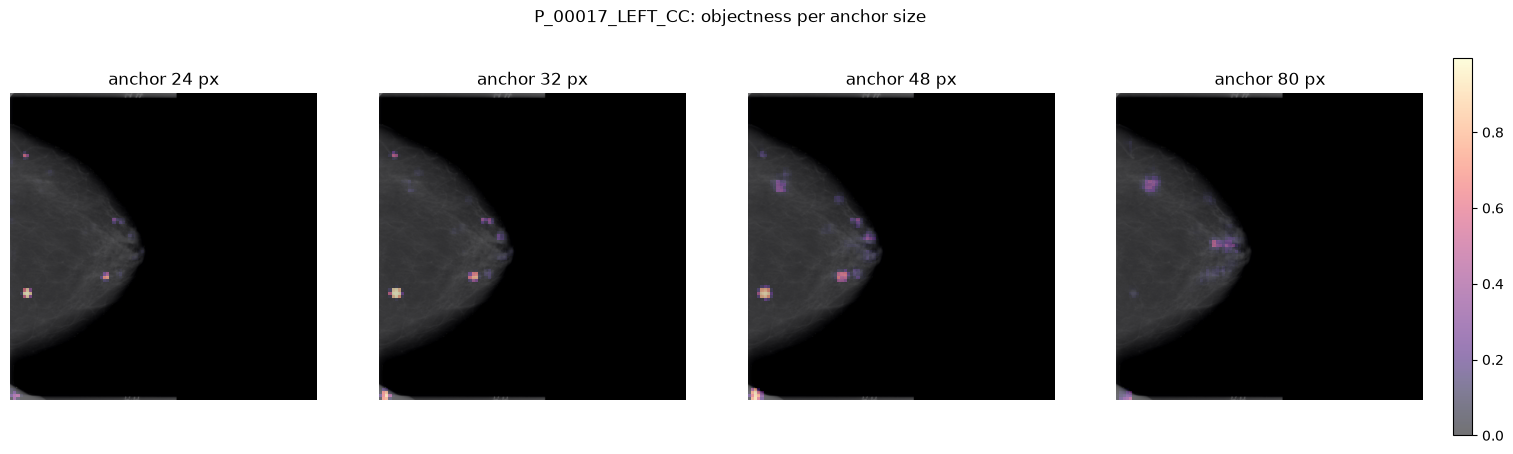

predict:   0%|          | 0/1 [00:00<?, ?it/s]

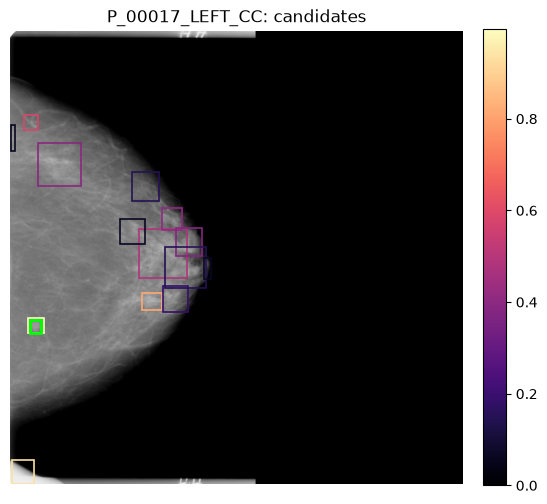

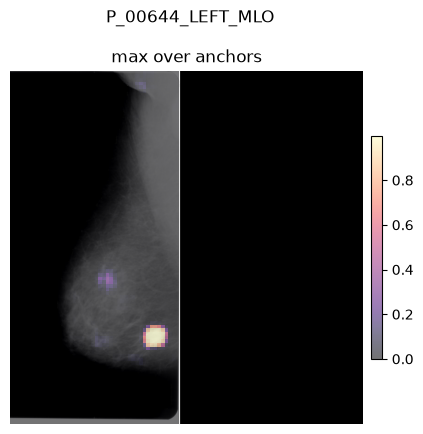

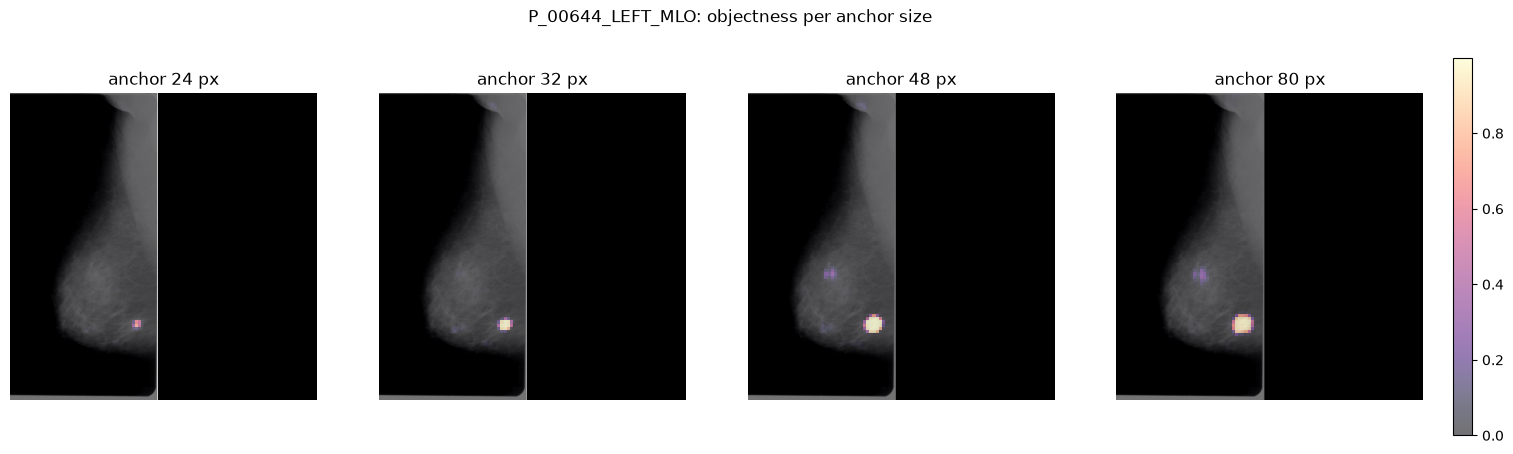

predict:   0%|          | 0/1 [00:00<?, ?it/s]

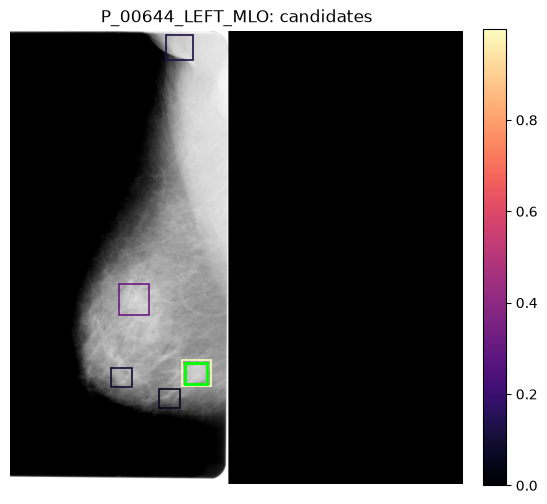

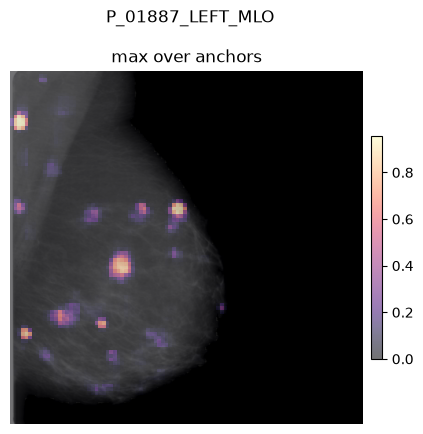

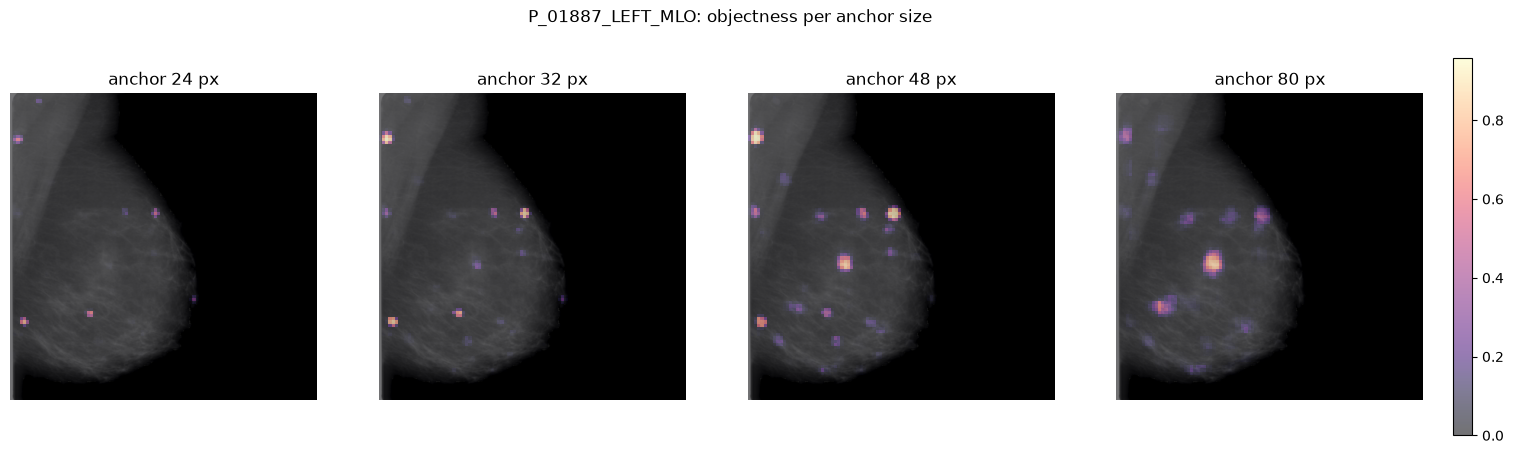

predict:   0%|          | 0/1 [00:00<?, ?it/s]

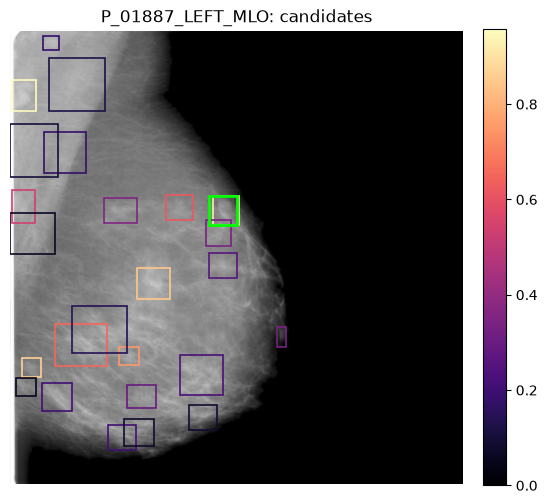

In [ ]:
# Block 14
# What the CNN sees on held-out mammograms: the objectness probability it puts on every anchor,
# the same map per anchor size, and the candidates it decodes at the low floor
scorer = CNN(config.fold_model_path("cnn", LESION_TYPE, config.VAL_FOLD))
scorer.load()

val_fold_df = trainval_df[trainval_df["fold"] == config.VAL_FOLD].reset_index(drop=True)

for index in np.linspace(0, len(val_fold_df) - 1, 3, dtype=int):
    row = val_fold_df.iloc[index]
    name = utility.mammogram_id(row.full_image)

    image, gt_boxes, _, objectness, _, breast = scorer.attention_map(row)
    gate = breast >= config.CNN_MASK_MIN_FRACTION

    utility.plot_heatmaps(image, [(objectness.max(axis=-1), "max over anchors")], name, mask=gate)

    utility.plot_heatmaps(
        image,
        [
            (values, f"anchor {size} px")
            for size, values in zip(config.CNN_ANCHOR_SIZES, np.moveaxis(objectness, -1, 0))
        ],
        f"{name}: objectness per anchor size",
        mask=gate,
    )

    entry = scorer.predict_raw(val_fold_df.iloc[[index]], score_threshold=config.CNN_SCORE_THRESHOLD)[0]
    utility.plot_boxes_by_score(image, entry["boxes"], entry["scores"], gt_boxes, f"{name}: candidates")